In [1]:
# ============================================================
# CELL 1: IMPORT LIBRARIES & SET RANDOM SEED
# ============================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)

# Set seed based on available device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
    torch.cuda.manual_seed_all(RANDOM_SEED)
else:
    device = torch.device("cpu")

print("="*50)
print("✅ Libraries Imported Successfully")
print("🔁 Random Seed Set to:", RANDOM_SEED)
print("💻 Device Selected:", device)
print("="*50)

✅ Libraries Imported Successfully
🔁 Random Seed Set to: 42
💻 Device Selected: mps


In [2]:
# ============================================================
# CELL 2: CONFIGURATION
# ============================================================

data_dir = os.path.join("..", "data")
batch_size = 32
num_epochs = 4 
learning_rate = 0.0001
num_workers = 2
early_stopping_patience = 3

print("="*50)
print("⚙️ Configuration Settings")
print(f"Device          : {device}")
print(f"Batch Size      : {batch_size}")
print(f"Epochs          : {num_epochs}")
print(f"Learning Rate   : {learning_rate}")
print(f"Patience        : {early_stopping_patience}")
print("="*50)

⚙️ Configuration Settings
Device          : mps
Batch Size      : 32
Epochs          : 4
Learning Rate   : 0.0001
Patience        : 3


In [3]:
# ============================================================
# CELL 3: DATA LOADING
# ============================================================

data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

full_dataset = datasets.ImageFolder(root=data_dir, transform=data_transforms)

class_names = full_dataset.classes
num_classes = len(class_names)

dataset_size = len(full_dataset)
train_size = int(0.8 * dataset_size)
val_size = dataset_size - train_size

train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(RANDOM_SEED)
)

train_loader = DataLoader(train_dataset, batch_size=batch_size,
                          shuffle=True, num_workers=num_workers)

val_loader = DataLoader(val_dataset, batch_size=batch_size,
                        shuffle=False, num_workers=num_workers)

print("="*60)
print("📂 Dataset Loaded")
print("Classes:", class_names)
print("Total Images:", dataset_size)
print("Train:", train_size)
print("Validation:", val_size)
print("="*60)

📂 Dataset Loaded
Classes: ['Cracking', 'Layer_shifting', 'Off_platform', 'Stringing', 'Warping']
Total Images: 1912
Train: 1529
Validation: 383


In [4]:
# ============================================================
# CELL 4: MODEL SETUP
# ============================================================

model = models.alexnet(pretrained=True)

num_features = model.classifier[6].in_features
model.classifier[6] = nn.Linear(num_features, num_classes)

# Freeze feature extractor
for param in model.features.parameters():
    param.requires_grad = False

model = model.to(device)

print("="*60)
print("🧠 AlexNet Modified for", num_classes, "Classes")
print("Classes:", class_names)
print("="*60)

/opt/anaconda3/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


🧠 AlexNet Modified for 5 Classes
Classes: ['Cracking', 'Layer_shifting', 'Off_platform', 'Stringing', 'Warping']


In [5]:
# ============================================================
# CELL 5: LOSS & OPTIMIZER
# ============================================================

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=learning_rate
)

trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("="*60)
print("🎯 Loss: CrossEntropyLoss")
print("🚀 Optimizer: Adam")
print("🔢 Trainable Parameters:", trainable_params)
print("="*60)

🎯 Loss: CrossEntropyLoss
🚀 Optimizer: Adam
🔢 Trainable Parameters: 54554629


In [6]:
# ============================================================
# CELL 6: TRAINING & EVALUATION FUNCTIONS
# ============================================================

def train_one_epoch(model, loader, criterion, optimizer, device, epoch):
    model.train()
    running_loss = 0.0
    running_corrects = 0
    total_samples = 0

    progress_bar = tqdm(loader, desc=f"Epoch {epoch+1}", unit="batch")

    for batch_idx, (inputs, labels) in enumerate(progress_bar):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        _, preds = torch.max(outputs, 1)

        running_loss += loss.item() * inputs.size(0)
        running_corrects += torch.sum(preds == labels).item()
        total_samples += inputs.size(0)

        progress_bar.set_postfix({
            "Batch": f"{batch_idx+1}/{len(loader)}",
            "Loss": f"{loss.item():.4f}"
        })

    epoch_loss = running_loss / total_samples
    epoch_acc = (running_corrects / total_samples) * 100

    return epoch_loss, epoch_acc


def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    total_samples = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            _, preds = torch.max(outputs, 1)

            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels).item()
            total_samples += inputs.size(0)

    epoch_loss = running_loss / total_samples
    epoch_acc = (running_corrects / total_samples) * 100

    return epoch_loss, epoch_acc

print("✅ Training Functions Ready")

✅ Training Functions Ready


In [7]:
# ============================================================
# CELL 7: TRAINING LOOP (WITH EARLY STOPPING)
# ============================================================

train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

best_val_loss = float("inf")
best_epoch = -1
epochs_no_improve = 0

print("="*60)
print("🚀 Starting Training")
print("="*60)

for epoch in range(num_epochs):

    train_loss, train_acc = train_one_epoch(
        model, train_loader, criterion, optimizer, device, epoch
    )

    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(f"\n📌 Epoch {epoch+1}/{num_epochs}")
    print(f"   📈 Train Loss: {train_loss:.4f} | Accuracy: {train_acc:.2f}%")
    print(f"   🧪 Val   Loss: {val_loss:.4f} | Accuracy: {val_acc:.2f}%")

    # Check for improvement in validation loss (early stopping on val_loss)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_epoch = epoch + 1
        epochs_no_improve = 0

        # Save best model checkpoint so far
        best_model_path = os.path.join("..", "models", "alexnet_best_model.pth")
        torch.save(model.state_dict(), best_model_path)
        print(f"   💾 New best model saved (epoch {best_epoch}, val_loss={best_val_loss:.4f})")
    else:
        epochs_no_improve += 1
        print(f"   ⏳ No improvement for {epochs_no_improve} epoch(s)")

        if epochs_no_improve >= early_stopping_patience:
            print(f"\n🛑 Early stopping triggered at epoch {epoch+1}")
            break

print("\n✅ Training Completed")
if best_epoch != -1:
    print(f"Best validation loss {best_val_loss:.4f} at epoch {best_epoch}")
print("="*60)

🚀 Starting Training


Epoch 1: 100%|██████████| 48/48 [04:41<00:00,  5.86s/batch, Batch=48/48, Loss=0.0968]



📌 Epoch 1/4
   📈 Train Loss: 0.5007 | Accuracy: 81.03%
   🧪 Val   Loss: 0.0625 | Accuracy: 98.43%
   💾 New best model saved (epoch 1, val_loss=0.0625)


Epoch 2: 100%|██████████| 48/48 [04:26<00:00,  5.55s/batch, Batch=48/48, Loss=0.0201]



📌 Epoch 2/4
   📈 Train Loss: 0.0651 | Accuracy: 97.97%
   🧪 Val   Loss: 0.0182 | Accuracy: 98.96%
   💾 New best model saved (epoch 2, val_loss=0.0182)


Epoch 3: 100%|██████████| 48/48 [02:33<00:00,  3.19s/batch, Batch=48/48, Loss=0.0612]



📌 Epoch 3/4
   📈 Train Loss: 0.0299 | Accuracy: 99.15%
   🧪 Val   Loss: 0.0212 | Accuracy: 98.96%
   ⏳ No improvement for 1 epoch(s)


Epoch 4: 100%|██████████| 48/48 [01:53<00:00,  2.37s/batch, Batch=48/48, Loss=0.0047]



📌 Epoch 4/4
   📈 Train Loss: 0.0216 | Accuracy: 99.35%
   🧪 Val   Loss: 0.0212 | Accuracy: 99.22%
   ⏳ No improvement for 2 epoch(s)

✅ Training Completed
Best validation loss 0.0182 at epoch 2


In [8]:
# ============================================================
# CELL 8: FINAL EVALUATION (LOAD BEST CHECKPOINT)
# ============================================================

best_model_path = os.path.join("..", "models", "alexnet_best_model.pth")

if os.path.exists(best_model_path):
    model.load_state_dict(torch.load(best_model_path, map_location=device))
    model = model.to(device)
    print(f"🔁 Loaded best model weights from '{best_model_path}' for evaluation.")
else:
    print(f"⚠️ Best model checkpoint '{best_model_path}' not found. Using last-epoch weights.")

# Evaluate on validation set (used here as test set)
test_loss, test_acc = evaluate(model, val_loader, criterion, device)

print("="*60)
print("🎯 FINAL PERFORMANCE (BEST CHECKPOINT)")
print("Test Loss    :", round(test_loss, 4))
print("Test Accuracy:", round(test_acc, 2), "%")
print("="*60)

🔁 Loaded best model weights from '../models/alexnet_best_model.pth' for evaluation.
🎯 FINAL PERFORMANCE (BEST CHECKPOINT)
Test Loss    : 0.0182
Test Accuracy: 98.96 %


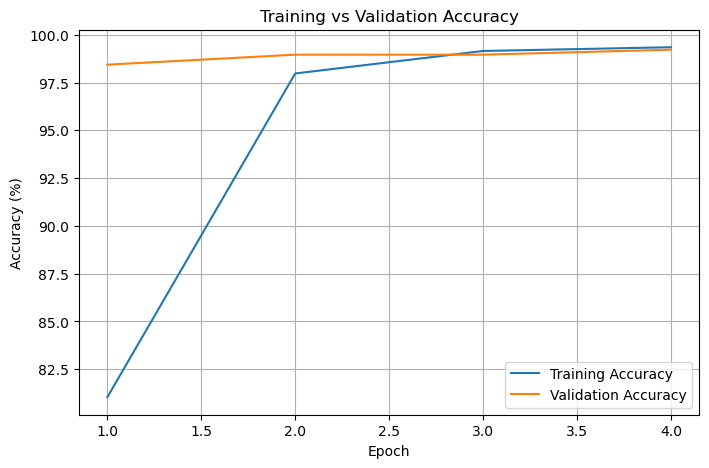

In [9]:
# ============================================================
# CELL 9: PLOT ACCURACY (USING ACTUAL EPOCH COUNT)
# ============================================================

# Because of early stopping, we may not reach `num_epochs`.
# Use the length of the logged accuracy lists as the true number of epochs.
num_trained_epochs = len(train_accuracies)
epochs = range(1, num_trained_epochs + 1)

plt.figure(figsize=(8,5))
plt.plot(epochs, train_accuracies, label='Training Accuracy')
plt.plot(epochs, val_accuracies, label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training vs Validation Accuracy')
plt.legend()
plt.grid(True)
plt.show()

In [10]:
# ============================================================
# CELL 10: SAVE MODEL
# ============================================================

final_model_path = os.path.join("..", "models", "alexnet_fdm_5class_model.pth")
torch.save(model.state_dict(), final_model_path)

print("💾 Model Saved Successfully!")

💾 Model Saved Successfully!


📊 CONFUSION MATRIX (VALUES)
Classes: ['Cracking', 'Layer_shifting', 'Off_platform', 'Stringing', 'Warping']

Confusion matrix (rows = actual, columns = predicted):
[[ 89   0   0   0   3]
 [  1  61   0   0   0]
 [  0   0  14   0   0]
 [  0   0   0 101   0]
 [  0   0   0   0 114]]

Confusion Matrix with Class Names:
                      Cracking Layer_shifting   Off_platform      Stringing        Warping
       Cracking             89              0              0              0              3
 Layer_shifting              1             61              0              0              0
   Off_platform              0              0             14              0              0
      Stringing              0              0              0            101              0
        Warping              0              0              0              0            114

📈 DETAILED CLASSIFICATION REPORT
                precision    recall  f1-score   support

      Cracking       0.99      0.97      0.98  

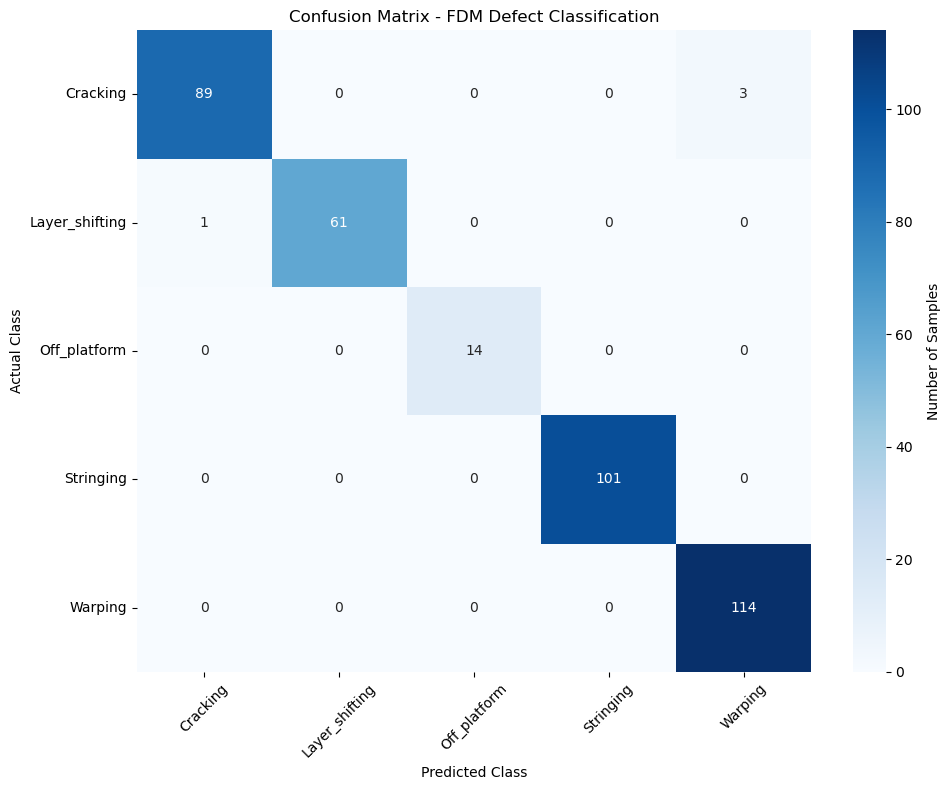

In [11]:
# ============================================================
# CELL 11: CONFUSION MATRIX (NUMERIC + HEATMAP)
# ============================================================

from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns

# Ensure model is in eval mode and best weights are loaded (Cell 8)
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)

print("=" * 60)
print("📊 CONFUSION MATRIX (VALUES)")
print("=" * 60)
print("Classes:", class_names)
print("\nConfusion matrix (rows = actual, columns = predicted):")
print(cm)

# Pretty print with labels
print("\nConfusion Matrix with Class Names:")
print(f"{'':>15}", end="")
for name in class_names:
    print(f"{name:>15}", end="")
print()

for i, actual_class in enumerate(class_names):
    print(f"{actual_class:>15}", end="")
    for j in range(len(class_names)):
        print(f"{cm[i, j]:>15}", end="")
    print()

# Classification report
print("\n" + "=" * 60)
print("📈 DETAILED CLASSIFICATION REPORT")
print("=" * 60)
report = classification_report(all_labels, all_preds, target_names=class_names)
print(report)

# Per-class accuracy
print("=" * 60)
print("🎯 PER-CLASS ACCURACY")
print("=" * 60)
for i, class_name in enumerate(class_names):
    correct = cm[i, i]
    total = cm[i, :].sum()
    acc = (correct / total) * 100 if total > 0 else 0
    print(f"{class_name:>15}: {correct:>3}/{total:>3} = {acc:6.2f}%")

print("=" * 60)

# Plot and save confusion matrix heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Number of Samples'})
plt.title('Confusion Matrix - FDM Defect Classification')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

# Save figure to file for use in report
fig_path = os.path.join("..", "figures", "confusion_matrix_alexnet_fdm_defects.png")
plt.savefig(fig_path, dpi=300)
plt.show()

# ============================================================
# SAVE METRICS & REPORT TO MARKDOWN FILE
# ============================================================

report_path = os.path.join("..", "reports", "AlexNet_FDM_3D_Printer_Defect_Classification_Report.md")

with open(report_path, "w") as f:
    f.write("# AlexNet - FDM 3D Printer Defect Classification\n\n")
    f.write("## Confusion Matrix (Numeric)\n\n")
    f.write("Classes: " + ", ".join(class_names) + "\n\n")
    f.write("Confusion matrix (rows = actual, columns = predicted):\n")
    f.write(np.array2string(cm) + "\n\n")

    f.write("## Classification Report\n\n")
    f.write(report + "\n\n")

    f.write("## Per-class Accuracy\n\n")
    for i, class_name in enumerate(class_names):
        correct = cm[i, i]
        total = cm[i, :].sum()
        acc = (correct / total) * 100 if total > 0 else 0
        f.write(f"{class_name}: {correct}/{total} = {acc:.2f}%\n")

    f.write("\n")
    f.write(f"Confusion matrix figure saved at: {fig_path}\n")
